## Import & Load data

In [ ]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

In [ ]:
CROP_FILE = '/content/drive/MyDrive/Studyspace/MoAI/S02_26/agronomy_new/crop_yield.csv'
SOIL_FILE = '/content/drive/MyDrive/Studyspace/MoAI/S02_26/agronomy_new/state_soil_data.csv'
WEATHER_FILE = '/content/drive/MyDrive/Studyspace/MoAI/S02_26/agronomy_new/state_weather_data_1997_2020.csv'

In [ ]:
crop_df = pd.read_csv(CROP_FILE)
soil_df = pd.read_csv(SOIL_FILE)
weather_df = pd.read_csv(WEATHER_FILE)

In [ ]:
def inspect_data(df, name):
  print(f'------{name}-----')
  print('Shape: ', df.shape)
  print('Cols: ', df.columns.tolist())
  print('Is null: ', df.isna().sum())
  print('Is duplicated: ', df.duplicated().any())
  print('\n',df.dtypes)

inspect_data(crop_df, "Crop Yield")
inspect_data(soil_df, "Soil")
inspect_data(weather_df, "Weather")

------Crop Yield-----
Shape:  (19689, 9)
Cols:  ['crop', 'year', 'season', 'state', 'area', 'production', 'fertilizer', 'pesticide', 'yield']
Is null:  crop          0
year          0
season        0
state         0
area          0
production    0
fertilizer    0
pesticide     0
yield         0
dtype: int64
Is duplicated:  False

 crop           object
year            int64
season         object
state          object
area          float64
production      int64
fertilizer    float64
pesticide     float64
yield         float64
dtype: object
------Soil-----
Shape:  (30, 5)
Cols:  ['state', 'N', 'P', 'K', 'pH']
Is null:  state    0
N        0
P        0
K        0
pH       0
dtype: int64
Is duplicated:  False

 state     object
N          int64
P          int64
K          int64
pH       float64
dtype: object
------Weather-----
Shape:  (720, 5)
Cols:  ['state', 'year', 'avg_temp_c', 'total_rainfall_mm', 'avg_humidity_percent']
Is null:  state                   0
year                    0
av

In [ ]:
crop_df.head()

,crop,year,season,state,area,production,fertilizer,pesticide,yield
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,7024878.38,22882.34,0.796087
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,631643.29,2057.47,0.710435
2,Castor seed,1997,Kharif,Assam,796.0,22,75755.32,246.76,0.238333
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,1870661.52,6093.36,5238.051739
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,165500.63,539.09,0.420909


In [ ]:
print(len(crop_df['crop'].unique()))
crop_df['crop'].unique()

55


array(['Arecanut', 'Arhar/Tur', 'Castor seed', 'Coconut ', 'Cotton(lint)',
       'Dry chillies', 'Gram', 'Jute', 'Linseed', 'Maize', 'Mesta',
       'Niger seed', 'Onion', 'Other  Rabi pulses', 'Potato',
       'Rapeseed &Mustard', 'Rice', 'Sesamum', 'Small millets',
       'Sugarcane', 'Sweet potato', 'Tapioca', 'Tobacco', 'Turmeric',
       'Wheat', 'Bajra', 'Black pepper', 'Cardamom', 'Coriander',
       'Garlic', 'Ginger', 'Groundnut', 'Horse-gram', 'Jowar', 'Ragi',
       'Cashewnut', 'Banana', 'Soyabean', 'Barley', 'Khesari', 'Masoor',
       'Moong(Green Gram)', 'Other Kharif pulses', 'Safflower',
       'Sannhamp', 'Sunflower', 'Urad', 'Peas & beans (Pulses)',
       'other oilseeds', 'Other Cereals', 'Cowpea(Lobia)',
       'Oilseeds total', 'Guar seed', 'Other Summer Pulses', 'Moth'],
      dtype=object)

In [ ]:
crop_df.loc[(crop_df['crop'] == "Coconut "), 'crop'] = 'Coconut'

In [ ]:
crop_df[crop_df['crop'] == 'Coconut'].head()

,crop,year,season,state,area,production,fertilizer,pesticide,yield
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,1870661.52,6093.36,5238.051739
60,Coconut,1997,Whole Year,Kerala,884344.0,5210000000,84163018.48,274146.64,5376.054286
94,Coconut,1997,Whole Year,West Bengal,24273.0,306202300,2310061.41,7524.63,13003.787780
150,Coconut,1998,Whole Year,Assam,20166.0,149866000,1992400.80,5848.14,6045.886957
178,Coconut,1998,Whole Year,Goa,24858.0,121000000,2455970.40,7208.82,4867.650000


In [ ]:
crop_df[(crop_df['crop'] == "Coconut ")]

,crop,year,season,state,area,production,fertilizer,pesticide,yield


In [ ]:
crop_df['crop'].unique()

array(['Arecanut', 'Arhar/Tur', 'Castor seed', 'Coconut', 'Cotton(lint)',
       'Dry chillies', 'Gram', 'Jute', 'Linseed', 'Maize', 'Mesta',
       'Niger seed', 'Onion', 'Other  Rabi pulses', 'Potato',
       'Rapeseed &Mustard', 'Rice', 'Sesamum', 'Small millets',
       'Sugarcane', 'Sweet potato', 'Tapioca', 'Tobacco', 'Turmeric',
       'Wheat', 'Bajra', 'Black pepper', 'Cardamom', 'Coriander',
       'Garlic', 'Ginger', 'Groundnut', 'Horse-gram', 'Jowar', 'Ragi',
       'Cashewnut', 'Banana', 'Soyabean', 'Barley', 'Khesari', 'Masoor',
       'Moong(Green Gram)', 'Other Kharif pulses', 'Safflower',
       'Sannhamp', 'Sunflower', 'Urad', 'Peas & beans (Pulses)',
       'other oilseeds', 'Other Cereals', 'Cowpea(Lobia)',
       'Oilseeds total', 'Guar seed', 'Other Summer Pulses', 'Moth'],
      dtype=object)

In [ ]:
crop_df['season'].unique()

array(['Whole Year ', 'Kharif     ', 'Rabi       ', 'Autumn     ',
       'Summer     ', 'Winter     '], dtype=object)

In [ ]:
print(len(crop_df['state'].unique()))
crop_df['state'].unique()


30


array(['Assam', 'Karnataka', 'Kerala', 'Meghalaya', 'West Bengal',
       'Puducherry', 'Goa', 'Andhra Pradesh', 'Tamil Nadu', 'Odisha',
       'Bihar', 'Gujarat', 'Madhya Pradesh', 'Maharashtra', 'Mizoram',
       'Punjab', 'Uttar Pradesh', 'Haryana', 'Himachal Pradesh',
       'Tripura', 'Nagaland', 'Chhattisgarh', 'Uttarakhand', 'Jharkhand',
       'Delhi', 'Manipur', 'Jammu and Kashmir', 'Telangana',
       'Arunachal Pradesh', 'Sikkim'], dtype=object)

In [ ]:
print(len(weather_df['state'].unique()))
weather_df['state'].unique()


30


array(['Andhra Pradesh', 'Arunachal Pradesh', 'Assam', 'Bihar',
       'Chhattisgarh', 'Delhi', 'Goa', 'Gujarat', 'Haryana',
       'Himachal Pradesh', 'Jharkhand', 'Jammu and Kashmir', 'Karnataka',
       'Kerala', 'Madhya Pradesh', 'Maharashtra', 'Manipur', 'Meghalaya',
       'Mizoram', 'Nagaland', 'Odisha', 'Puducherry', 'Punjab', 'Sikkim',
       'Tamil Nadu', 'Telangana', 'Tripura', 'Uttar Pradesh',
       'Uttarakhand', 'West Bengal'], dtype=object)

In [ ]:
set(weather_df['state'].unique()) == set(crop_df['state'].unique()) == set(soil_df['state'].unique())

True

In [ ]:
print(len(crop_df['year'].unique()))
crop_df['year'].unique()

24


array([1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007,
       2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018,
       2019, 2020])

## Standardise column names

In [ ]:
def clean_column_names(df):
  df = df.copy()
  df.columns = (
      df.columns.str.strip().str.lower()
      .str.replace(" ", "_")
      .str.replace(r"[^a-z0-9_]", "", regex=True)
  )
  return df

In [ ]:
crop_df = clean_column_names(crop_df)
soil_df = clean_column_names(soil_df)
weather_df = clean_column_names(weather_df)

## Detect outliers

In [ ]:
## Calculate IQR
def iqr_boundaries(col):
    q1 = col.quantile(0.25)
    q3 = col.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    return lower_bound, upper_bound

def zscore_outliers(data, threshold=3):
  data = np.array(data)
  mean = np.mean(data)
  std = np.std(data)

  z_scores = (data - mean)/std
  outliers = data[np.abs(z_scores) > threshold]
  outlier_indices = np.where(np.abs(z_scores) > threshold)[0]

  return outliers, outlier_indices, z_scores


In [ ]:
crop_df.dtypes

,0
crop,object
year,int64
season,object
state,object
area,float64
production,int64
fertilizer,float64
pesticide,float64
yield,float64


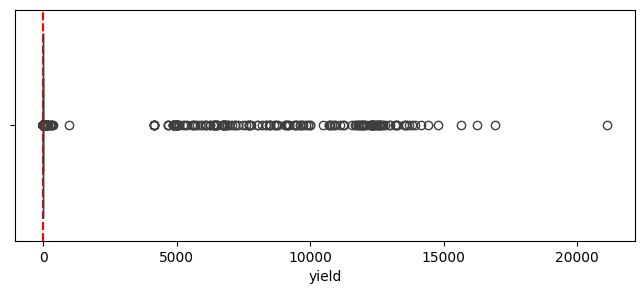

In [ ]:
from matplotlib.lines import lineStyles
lower, upper = iqr_boundaries(crop_df['yield'])

plt.figure(figsize=(8,3))
sns.boxplot(x=crop_df['yield'])
plt.axvline(x=lower, color='r', linestyle='--')
plt.axvline(x=upper, color='r', linestyle='--')

plt.show()

In [ ]:
iqr_outliers = crop_df[(crop_df['yield'] < lower) | (crop_df['yield'] > upper)]
iqr_outliers.shape

(3065, 9)

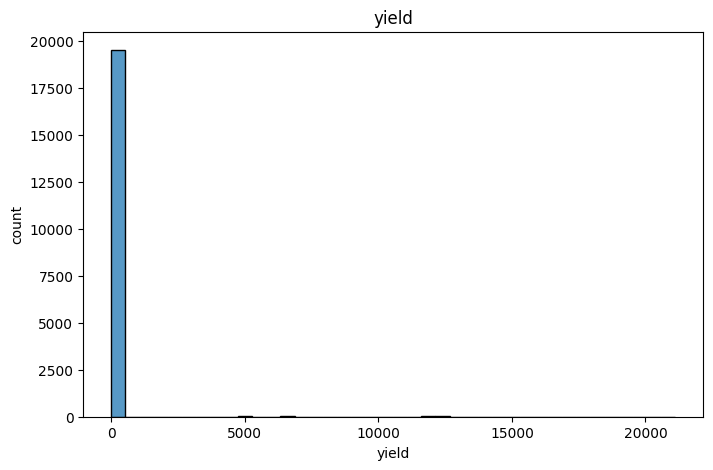

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(data=crop_df['yield'], bins=40)
plt.title('yield')
plt.ylabel('count')
plt.show()

In [ ]:
## Outliers by z-score
from scipy.stats import zscore
crop_df['yield_zscore'] = zscore(crop_df['yield'], nan_policy="omit")

yield_outliers = crop_df[crop_df['yield_zscore'].abs() > 3]

print(yield_outliers['crop'].unique())
yield_outliers.sort_values(by='yield_zscore').head(10)

['Coconut']


,crop,year,season,state,area,production,fertilizer,pesticide,yield,yield_zscore
2086,Coconut,2006,Whole Year,Karnataka,403671.0,1635839000,51552823.41,88807.62,4164.715926,4.650845
861,Coconut,2001,Whole Year,Karnataka,369828.0,1503638000,37770533.64,96155.28,4164.951481,4.651113
8065,Coconut,2002,Whole Year,Karnataka,375425.0,1525287000,35541484.75,93856.25,4165.087778,4.651268
1327,Coconut,2003,Whole Year,Karnataka,375957.0,1529139000,37212223.86,90229.68,4165.193333,4.651388
1531,Coconut,2004,Whole Year,Karnataka,383206.0,1551729000,41516538.04,80473.26,4165.395185,4.651618
1759,Coconut,2005,Whole Year,Karnataka,395885.0,1606890000,47474529.20,83135.85,4165.660741,4.651920
592,Coconut,2000,Whole Year,Karnataka,335996.0,1762403000,32984727.32,87358.96,4673.661111,5.230321
6764,Coconut,1999,Whole Year,Karnataka,321158.0,1671774000,34084498.54,86712.66,4680.495926,5.238104
195,Coconut,1998,Whole Year,Karnataka,310399.0,1611530000,30667421.20,90015.71,4692.261111,5.251499
1309,Coconut,2003,Whole Year,Goa,25110.0,122220000,2485387.80,6026.40,4867.380000,5.450887


In [ ]:
yield_outliers.shape

(164, 10)

In [ ]:
crop_df[crop_df['crop'] == 'Coconut'].shape

(172, 10)

All outliers detected by z-scores are coconut yield -> because the weight of coconut is much higher than other crop <br>
Because of timeseries data --> remove all coconut row

In [ ]:
## Remove coconut
# outlier_indices = yield_outliers.index
# crop_df = crop_df.drop(outlier_indices, axis=0)
drop_indices = crop_df[crop_df['crop'] == 'Coconut'].index
crop_df = crop_df.drop(drop_indices, axis=0)

display(crop_df.shape)
display(crop_df.head())


(19517, 10)

,crop,year,season,state,area,production,fertilizer,pesticide,yield,yield_zscore
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,7024878.38,22882.34,0.796087,-0.090128
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,631643.29,2057.47,0.710435,-0.090225
2,Castor seed,1997,Kharif,Assam,796.0,22,75755.32,246.76,0.238333,-0.090763
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,165500.63,539.09,0.420909,-0.090555
5,Dry chillies,1997,Whole Year,Assam,13587.0,9073,1293074.79,4211.97,0.643636,-0.090302


In [ ]:
crop_df.shape

(19517, 10)

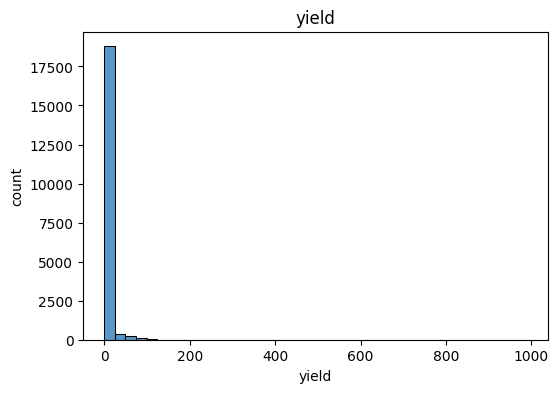

In [ ]:
plt.figure(figsize=(6,4))
sns.histplot(data=crop_df['yield'], bins=40)
plt.title('yield')
plt.ylabel('count')
plt.show()

## Merge the datasets

In [ ]:
merged_df = crop_df.merge(
    weather_df, on=["state", 'year'], how='left'
)

merged_df = merged_df.merge(
    soil_df, on='state', how='left'
)
print(merged_df.shape)
merged_df.head()

(19517, 17)


,crop,year,season,state,area,production,fertilizer,pesticide,yield,yield_zscore,avg_temp_c,total_rainfall_mm,avg_humidity_percent,n,p,k,ph
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,7024878.38,22882.34,0.796087,-0.090128,22.41,1468.92,70.71,60,18,38,5.8
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,631643.29,2057.47,0.710435,-0.090225,22.41,1468.92,70.71,60,18,38,5.8
2,Castor seed,1997,Kharif,Assam,796.0,22,75755.32,246.76,0.238333,-0.090763,22.41,1468.92,70.71,60,18,38,5.8
3,Cotton(lint),1997,Kharif,Assam,1739.0,794,165500.63,539.09,0.420909,-0.090555,22.41,1468.92,70.71,60,18,38,5.8
4,Dry chillies,1997,Whole Year,Assam,13587.0,9073,1293074.79,4211.97,0.643636,-0.090302,22.41,1468.92,70.71,60,18,38,5.8


### Clean categorical values

In [ ]:
## Clean categorical values
def clean_categorical_values(col_values):
    clean = (
        col_values.str.strip()
        .str.lower()
        .str.replace(" ", "_")
        .str.replace("-", "_")
    )
    return clean

In [ ]:
merged_df.columns

Index(['crop', 'year', 'season', 'state', 'yield', 'avg_temp_c',
       'total_rainfall_mm', 'avg_humidity_percent', 'n', 'p', 'k', 'ph',
       'fertilizer_rate', 'pesticide_rate'],
      dtype='object')

In [ ]:
cate_cols = ['crop', 'season', 'state']
for col in cate_cols:
    merged_df[col] = clean_categorical_values(merged_df[col])
    print(f'{col} unique values ({len(merged_df[col].unique())}):\n\t {merged_df[col].unique()}')

crop unique values (54):
	 ['arecanut' 'arhar/tur' 'castor_seed' 'cotton(lint)' 'dry_chillies' 'gram'
 'jute' 'linseed' 'maize' 'mesta' 'niger_seed' 'onion'
 'other__rabi_pulses' 'potato' 'rapeseed_&mustard' 'rice' 'sesamum'
 'small_millets' 'sugarcane' 'sweet_potato' 'tapioca' 'tobacco' 'turmeric'
 'wheat' 'bajra' 'black_pepper' 'cardamom' 'coriander' 'garlic' 'ginger'
 'groundnut' 'horse_gram' 'jowar' 'ragi' 'cashewnut' 'banana' 'soyabean'
 'barley' 'khesari' 'masoor' 'moong(green_gram)' 'other_kharif_pulses'
 'safflower' 'sannhamp' 'sunflower' 'urad' 'peas_&_beans_(pulses)'
 'other_oilseeds' 'other_cereals' 'cowpea(lobia)' 'oilseeds_total'
 'guar_seed' 'other_summer_pulses' 'moth']
season unique values (6):
	 ['whole_year' 'kharif' 'rabi' 'autumn' 'summer' 'winter']
state unique values (30):
	 ['assam' 'karnataka' 'kerala' 'meghalaya' 'west_bengal' 'puducherry' 'goa'
 'andhra_pradesh' 'tamil_nadu' 'odisha' 'bihar' 'gujarat' 'madhya_pradesh'
 'maharashtra' 'mizoram' 'punjab' 'uttar_p

## Exploratory Analysis

### Remove unused columns and create new columns
- Yield = Production / Area
- fertilizer_rate = fertilizer / area
- pesticide_rate = pesticide / area
- Target value: Yield

In [ ]:
## Create new columns
merged_df['fertilizer_rate'] = merged_df['fertilizer'] / merged_df['area']
merged_df['pesticide_rate'] = merged_df['pesticide'] / merged_df['area']

merged_df.shape

(19517, 19)

In [ ]:
## Remove production and area columns
merged_df = merged_df.drop(['area', 'production'], axis=1)
merged_df.shape

(19517, 17)

In [ ]:
## Remove fertilizer and pesticide
merged_df = merged_df.drop(['fertilizer', 'pesticide'], axis=1)
merged_df.shape

(19517, 15)

In [ ]:
## Remove yield_zscore
merged_df = merged_df.drop('yield_zscore', axis=1)
merged_df.shape

(19517, 14)

In [ ]:
merged_df.head()

,crop,year,season,state,yield,avg_temp_c,total_rainfall_mm,avg_humidity_percent,n,p,k,ph,fertilizer_rate,pesticide_rate
0,Arecanut,1997,Whole Year,Assam,0.796087,22.41,1468.92,70.71,60,18,38,5.8,95.17,0.31
1,Arhar/Tur,1997,Kharif,Assam,0.710435,22.41,1468.92,70.71,60,18,38,5.8,95.17,0.31
2,Castor seed,1997,Kharif,Assam,0.238333,22.41,1468.92,70.71,60,18,38,5.8,95.17,0.31
3,Cotton(lint),1997,Kharif,Assam,0.420909,22.41,1468.92,70.71,60,18,38,5.8,95.17,0.31
4,Dry chillies,1997,Whole Year,Assam,0.643636,22.41,1468.92,70.71,60,18,38,5.8,95.17,0.31


In [ ]:
test = merged_df.loc[merged_df['state'] == 'Assam']
# test.groupby('fertilizer_rate').value_counts()
test['fertilizer_rate'].sort_values().unique()

array([ 94.67      ,  94.67      ,  94.67000003,  95.17      ,
        95.17      ,  95.17000002,  98.17      ,  98.17      ,
        98.17      ,  98.17000001,  98.8       ,  98.8       ,
        98.97999998,  98.98      ,  98.98      , 102.13      ,
       102.13      , 102.13000001, 106.12999999, 106.13      ,
       106.13      , 108.34      , 108.34      , 108.34      ,
       119.92      , 119.92      , 119.92      , 127.71      ,
       127.71      , 127.71000002, 133.4       , 133.4       ,
       143.03999998, 143.04      , 143.04      , 144.48999998,
       144.49      , 144.49      , 150.8       , 150.8       ,
       150.96      , 150.96      , 150.96000002, 153.25      ,
       155.82      , 155.82      , 155.82000001, 157.43999999,
       157.44      , 157.44      , 157.90999998, 157.91      ,
       157.91      , 162.2       , 162.2       , 166.10999999,
       166.11      , 166.11      , 167.51999999, 167.52      ,
       167.52      , 171.76      , 171.76      , 171.76

In [ ]:
print(f'{len(merged_df['state'].unique())} states: {merged_df['state'].unique()}')
print(f'\n{len(merged_df['crop'].unique())} crop types: {merged_df['crop'].unique()}')
print(f'\n{len(merged_df['year'].unique())} years: {merged_df['year'].unique()}')


30 states: ['Assam' 'Karnataka' 'Kerala' 'Meghalaya' 'West Bengal' 'Puducherry' 'Goa'
 'Andhra Pradesh' 'Tamil Nadu' 'Odisha' 'Bihar' 'Gujarat' 'Madhya Pradesh'
 'Maharashtra' 'Mizoram' 'Punjab' 'Uttar Pradesh' 'Haryana'
 'Himachal Pradesh' 'Tripura' 'Nagaland' 'Chhattisgarh' 'Uttarakhand'
 'Jharkhand' 'Delhi' 'Manipur' 'Jammu and Kashmir' 'Telangana'
 'Arunachal Pradesh' 'Sikkim']

54 crop types: ['Arecanut' 'Arhar/Tur' 'Castor seed' 'Cotton(lint)' 'Dry chillies' 'Gram'
 'Jute' 'Linseed' 'Maize' 'Mesta' 'Niger seed' 'Onion'
 'Other  Rabi pulses' 'Potato' 'Rapeseed &Mustard' 'Rice' 'Sesamum'
 'Small millets' 'Sugarcane' 'Sweet potato' 'Tapioca' 'Tobacco' 'Turmeric'
 'Wheat' 'Bajra' 'Black pepper' 'Cardamom' 'Coriander' 'Garlic' 'Ginger'
 'Groundnut' 'Horse-gram' 'Jowar' 'Ragi' 'Cashewnut' 'Banana' 'Soyabean'
 'Barley' 'Khesari' 'Masoor' 'Moong(Green Gram)' 'Other Kharif pulses'
 'Safflower' 'Sannhamp' 'Sunflower' 'Urad' 'Peas & beans (Pulses)'
 'other oilseeds' 'Other Cereals' 'Cowpea(

In [ ]:
merged_df.describe()

,year,yield,avg_temp_c,total_rainfall_mm,avg_humidity_percent,n,p,k,ph,fertilizer_rate,pesticide_rate
count,19517.000000,19517.000000,19517.000000,19517.000000,19517.000000,19517.000000,19517.000000,19517.000000,19517.000000,19517.000000,19517.000000
mean,2009.130092,4.410025,23.989030,1337.075447,64.601865,76.652508,33.475380,32.198084,6.642527,137.173077,0.274395
std,6.498446,14.587785,4.419116,638.513277,11.488365,20.126867,11.557416,7.885122,0.691825,26.200396,0.073289
min,1997.000000,0.000000,6.260000,249.240000,34.470000,50.000000,15.000000,20.000000,5.500000,94.670000,0.090000
25%,2004.000000,0.596875,22.890000,894.160000,54.600000,65.000000,24.000000,25.000000,6.000000,108.340000,0.220000
50%,2010.000000,1.020000,25.540000,1172.020000,67.960000,72.000000,38.000000,33.000000,6.600000,144.490000,0.270000
75%,2015.000000,2.320000,26.790000,1606.860000,73.690000,80.000000,43.000000,38.000000,7.100000,157.910000,0.330000
max,2020.000000,989.870000,28.630000,5244.360000,86.060000,150.000000,55.000000,50.000000,8.000000,193.610000,0.380000


In [ ]:
merged_df.isna().sum()

,0
crop,0
year,0
season,0
state,0
yield,0
avg_temp_c,0
total_rainfall_mm,0
avg_humidity_percent,0
n,0
p,0


In [ ]:
merged_df.duplicated().any()

np.False_

In [ ]:
merged_df['year'] = merged_df['year'].astype(str)
merged_df.head()

,crop,year,season,state,yield,avg_temp_c,total_rainfall_mm,avg_humidity_percent,n,p,k,ph,fertilizer_rate,pesticide_rate
0,Arecanut,1997,Whole Year,Assam,0.796087,22.41,1468.92,70.71,60,18,38,5.8,95.17,0.31
1,Arhar/Tur,1997,Kharif,Assam,0.710435,22.41,1468.92,70.71,60,18,38,5.8,95.17,0.31
2,Castor seed,1997,Kharif,Assam,0.238333,22.41,1468.92,70.71,60,18,38,5.8,95.17,0.31
3,Cotton(lint),1997,Kharif,Assam,0.420909,22.41,1468.92,70.71,60,18,38,5.8,95.17,0.31
4,Dry chillies,1997,Whole Year,Assam,0.643636,22.41,1468.92,70.71,60,18,38,5.8,95.17,0.31


### Crop yield


In [ ]:
numerical_cols = merged_df.select_dtypes(include=np.number).columns.tolist()
numerical_cols

['yield',
 'avg_temp_c',
 'total_rainfall_mm',
 'avg_humidity_percent',
 'n',
 'p',
 'k',
 'ph',
 'fertilizer_rate',
 'pesticide_rate']

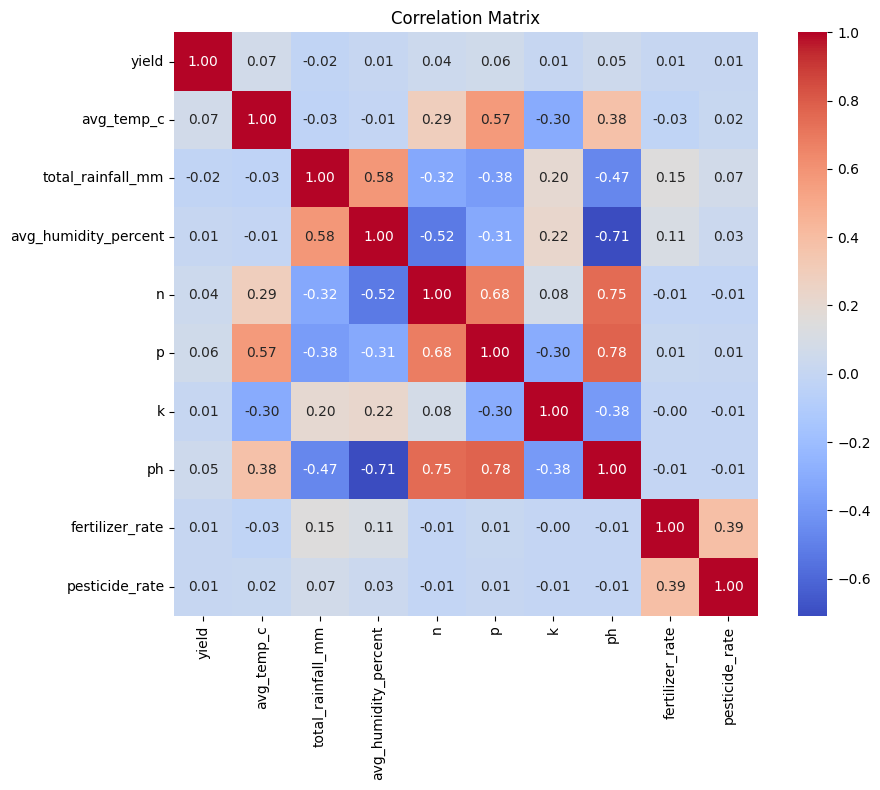

In [ ]:
corr_matrix = merged_df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    data=corr_matrix,
    cmap='coolwarm',
    annot=True,
    fmt='.2f',
    square=True
)

plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

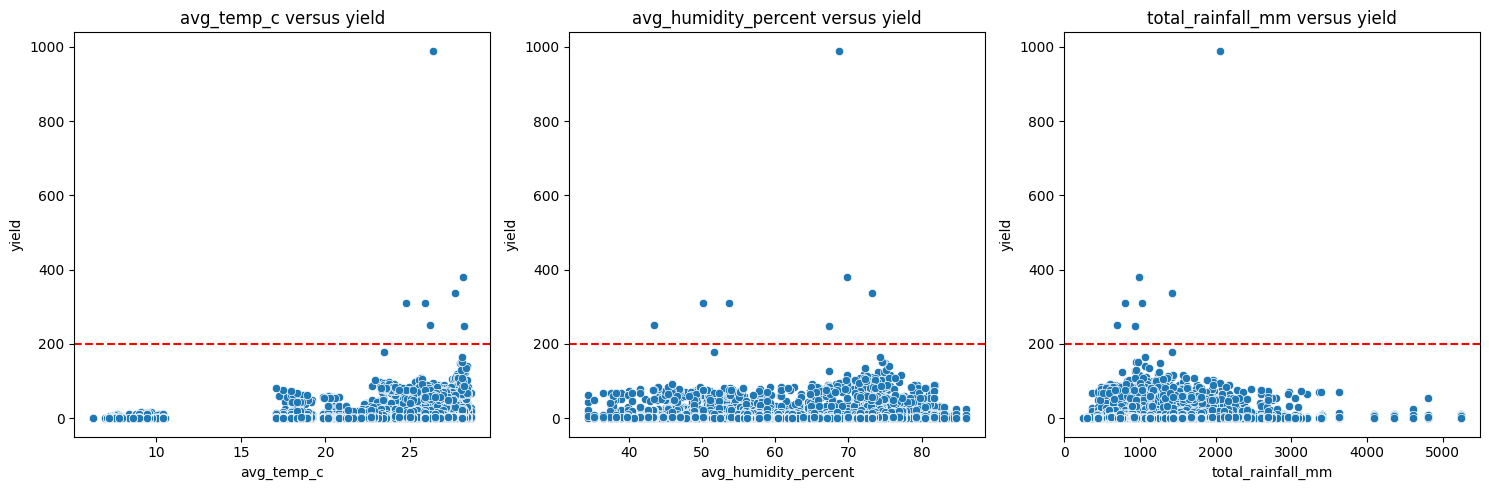

In [ ]:
cols = ['avg_temp_c', 'avg_humidity_percent', 'total_rainfall_mm']
n_rows = 1

fig, axes = plt.subplots(n_rows, len(cols), figsize=(15, 5))
axes=axes.flatten()

for ax, col in zip(axes, cols):
  sns.scatterplot(data=merged_df, x=col, y='yield', ax=ax)
  ax.set_title(f'{col} versus yield')
  ax.axhline(y=200, color='r', linestyle='--')
plt.tight_layout()
plt.show()

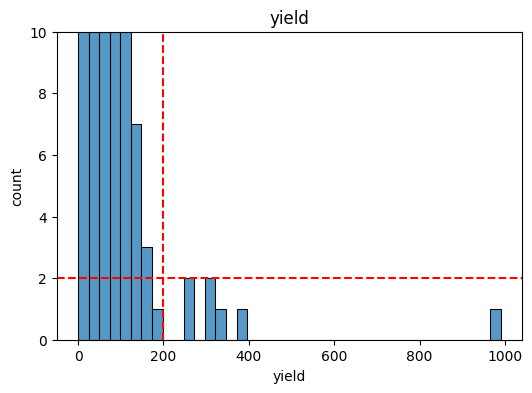

In [ ]:
plt.figure(figsize=(6,4))
sns.histplot(data=merged_df['yield'], bins=40)
plt.title('yield')
plt.ylabel('count')
plt.ylim(0, 10)
plt.axhline(y=2, color='r', linestyle='--')
plt.axvline(x=200, color='r', linestyle='--')
plt.show()

In [ ]:
yield_outliers = merged_df[(merged_df['yield'] > 200)]
print(yield_outliers.shape)
yield_outliers.head()

(7, 14)


,crop,year,season,state,yield,avg_temp_c,total_rainfall_mm,avg_humidity_percent,n,p,k,ph,fertilizer_rate,pesticide_rate
2655,Cashewnut,2008,Whole Year,Tamil Nadu,338.548966,27.66,1428.04,73.16,80,38,30,6.6,143.04,0.09
4987,Onion,2017,Kharif,Andhra Pradesh,381.420000,28.14,991.20,69.86,78,45,22,6.8,157.44,0.38
5328,Onion,2018,Kharif,Andhra Pradesh,247.572727,28.18,927.05,67.40,78,45,22,6.8,162.20,0.35
6122,Maize,1997,Autumn,Maharashtra,989.870000,26.37,2053.66,68.68,75,43,26,7.1,95.17,0.31
17698,Potato,2009,Whole Year,Delhi,249.990000,26.20,698.05,43.39,90,40,30,7.5,155.82,0.17


In [ ]:
merged_df.shape

(19517, 14)

In [ ]:
merged_df = merged_df.drop(yield_outliers.index, axis=0)
merged_df.shape

(19510, 14)

In [ ]:
## Avg yield by year
merged_df.groupby('year')['yield'].mean()

,yield
year,
1997,3.894809
1998,4.333287
1999,4.358907
2000,3.929774
2001,3.940790
2002,3.833093
2003,3.995923
2004,3.914888
2005,4.131569


In [ ]:
## by crop
merged_df.groupby('crop')['yield'].mean()

,yield
crop,
Arecanut,2.073635
Arhar/Tur,0.967348
Bajra,2.427462
Banana,26.851128
Barley,1.595540
Black pepper,0.829605
Cardamom,0.168355
Cashewnut,0.598419
Castor seed,0.693609


In [ ]:
# by state
merged_df.groupby('state')['yield'].mean()

,yield
state,
Andhra Pradesh,4.935353
Arunachal Pradesh,3.735060
Assam,3.578857
Bihar,3.476499
Chhattisgarh,1.981895
Delhi,8.955400
Goa,6.767118
Gujarat,6.697227
Haryana,5.532732


## Building models

#### Split target

In [ ]:
merged_df.dtypes

,0
crop,object
year,object
season,object
state,object
yield,float64
avg_temp_c,float64
total_rainfall_mm,float64
avg_humidity_percent,float64
n,int64
p,int64


In [ ]:
target = 'yield'
numeric_features = merged_df.select_dtypes(include=np.number).columns.tolist()
numeric_features = list(set(numeric_features) - set(['yield']))
numeric_features

['ph',
 'pesticide_rate',
 'avg_humidity_percent',
 'avg_temp_c',
 'n',
 'p',
 'fertilizer_rate',
 'total_rainfall_mm',
 'k']

In [ ]:
categorical_features = ['crop', 'state', 'season']

In [ ]:
X = merged_df[numeric_features + categorical_features]
y = merged_df[target]

### Preprocessing

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


In [ ]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),

])

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

### Train test split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=25
)

### Linear Regression

In [ ]:
mlr_model = Pipeline([
    ('preprocessing', preprocessor),
    ('model', LinearRegression())
])

mlr_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['p', 'k', 'fertilizer_rate',
                                                   'pesticide_rate', 'ph',
                                                   'avg_temp_c', 'n',
                                                   'avg_humidity_percent',
                                                   'total_rainfall_mm']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['crop', 'state',
                                                   'season'])])),
                ('model', LinearRegression())])

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

predictions = mlr_model.predict(X_test)
mae = mean_absolute_error(y_test, predictions)
rmse = mean_squared_error(y_test, predictions) ** 0.5
r2 = r2_score(y_test, predictions)

print('MAE: ', mae)
print('RMSE: ', rmse)
print('R2 Score: ', r2)

MAE:  2.7016092663759395
RMSE:  6.36805967142014
R2 Score:  0.7040021210438008


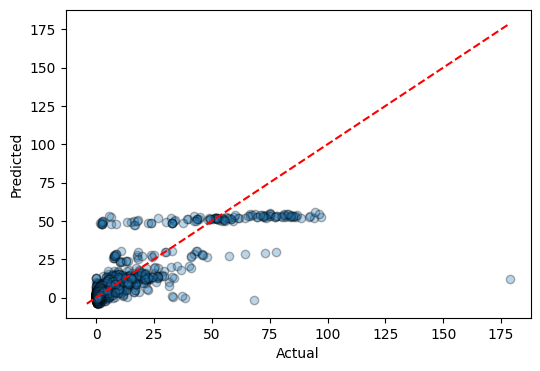

In [ ]:
## Actual vs predicted
plt.figure(figsize=(6, 4))

plt.scatter(x=y_test, y=predictions, alpha=0.3, edgecolors='k')
lo = min(y_test.min(), predictions.min())
hi = max(y_test.max(), predictions.max())
plt.plot([lo, hi], [lo, hi], "r--", lw=1.5, label="Perfect prediction")
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.show()

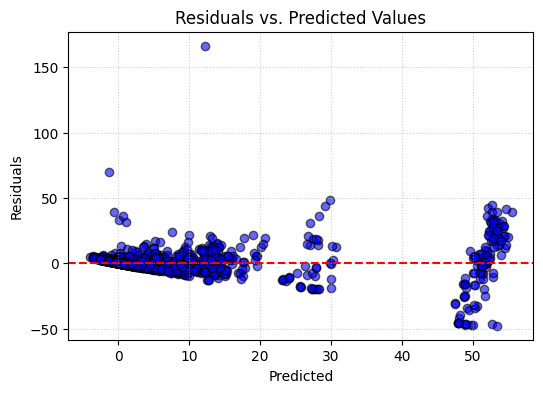

In [ ]:
# Residual plot
residuals = y_test - predictions

plt.figure(figsize=(6, 4))
plt.scatter(predictions, residuals, color='blue', alpha=0.6, edgecolors='k')

# Add a horizontal reference line at y = 0
plt.axhline(y=0, color='red', linestyle='--', linewidth=1.5)

# Axis labels and styling
plt.title('Residuals vs. Predicted Values')
plt.xlabel('Predicted')
plt.ylabel('Residuals')
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()

### Random Forest regressor


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV, learning_curve

#### RF 1

In [ ]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1,
    )),
])

rf_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['p', 'k', 'fertilizer_rate',
                                                   'pesticide_rate', 'ph',
                                                   'avg_temp_c', 'n',
                                                   'avg_humidity_percent',
                                                   'total_rainfall_mm']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['crop', 'state',
                                                   'season'])])),
                ('regressor',
                 RandomForestRegressor(n_estimators=300, n_jobs=-1,
                                       random_state=42))])

In [ ]:
y_pred = rf_model.predict(X_test)

r2 = r2_score(y_test, y_pred)
rmse = (mean_squared_error(y_test, y_pred))**0.5
mae = mean_absolute_error(y_test, y_pred)

print('MAE: ', mae)
print('RMSE: ', rmse)
print('R2 Score: ', r2)

MAE:  0.7755475572270618
RMSE:  3.8511653473843848
R2 Score:  0.8917423287034758


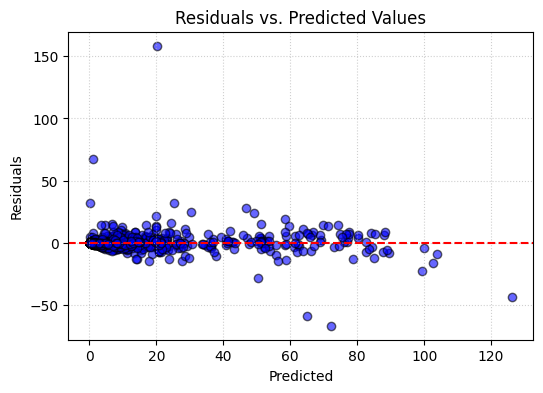

In [ ]:
# Residual plot
residuals = y_test - y_pred

plt.figure(figsize=(6, 4))
plt.scatter(y_pred, residuals, color='blue', alpha=0.6, edgecolors='k')

# Add a horizontal reference line at y = 0
plt.axhline(y=0, color='red', linestyle='--', linewidth=1.5)

# Axis labels and styling
plt.title('Residuals vs. Predicted Values')
plt.xlabel('Predicted')
plt.ylabel('Residuals')
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()

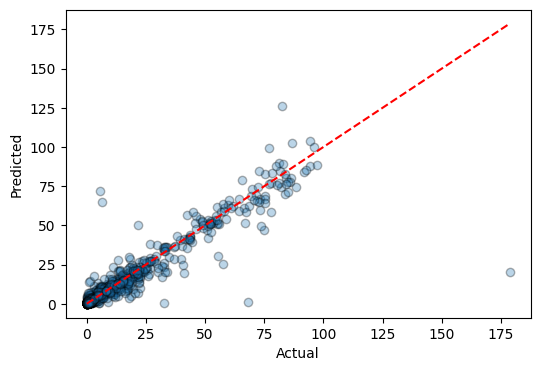

In [ ]:
## Actual vs predicted
plt.figure(figsize=(6, 4))

plt.scatter(x=y_test, y=y_pred, alpha=0.3, edgecolors='k')
lo = min(y_test.min(), y_pred.min())
hi = max(y_test.max(), y_pred.max())
plt.plot([lo, hi], [lo, hi], "r--", lw=1.5, label="Perfect prediction")

plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.show()

#### Hyperparameter tuning

In [ ]:
## Random Forest pipeline
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

In [ ]:
## Hyperparameter search space
rf_params = {
    "regressor__n_estimators": [ 200, 500, 800],
    "regressor__max_depth": [20, 30],
    "regressor__min_samples_leaf": [4, 8]
}


In [ ]:
## Hyperparameter tuning
rf_search = RandomizedSearchCV(
    estimator= rf_pipeline,
    param_distributions= rf_params,
    n_iter=30,
    cv=5,
    scoring= "neg_root_mean_squared_error"
)

rf_search.fit(X_train, y_train)

print("Best parameters:")
for parameter, value in rf_search.best_params_.items():
    print(f"{parameter}: {value}")

print("\nBest cross-validation RMSE:",
      -rf_search.best_score_)

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 12 is smaller than n_iter=30. Running 12 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Best parameters:
regressor__n_estimators: 200
regressor__min_samples_leaf: 4
regressor__max_depth: 30

Best cross-validation RMSE: 3.004131225248767


In [ ]:
best_rf_model = rf_search.best_estimator_

y_pred = best_rf_model.predict(X_test)

In [ ]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\nTest-set performance")
print(f"MAE:      {mae:.4f}")
print(f"RMSE:     {rmse:.4f}")
print(f"R2 Score: {r2:.4f}")


Test-set performance
MAE:      0.8515
RMSE:     3.8498
R2 Score: 0.8918


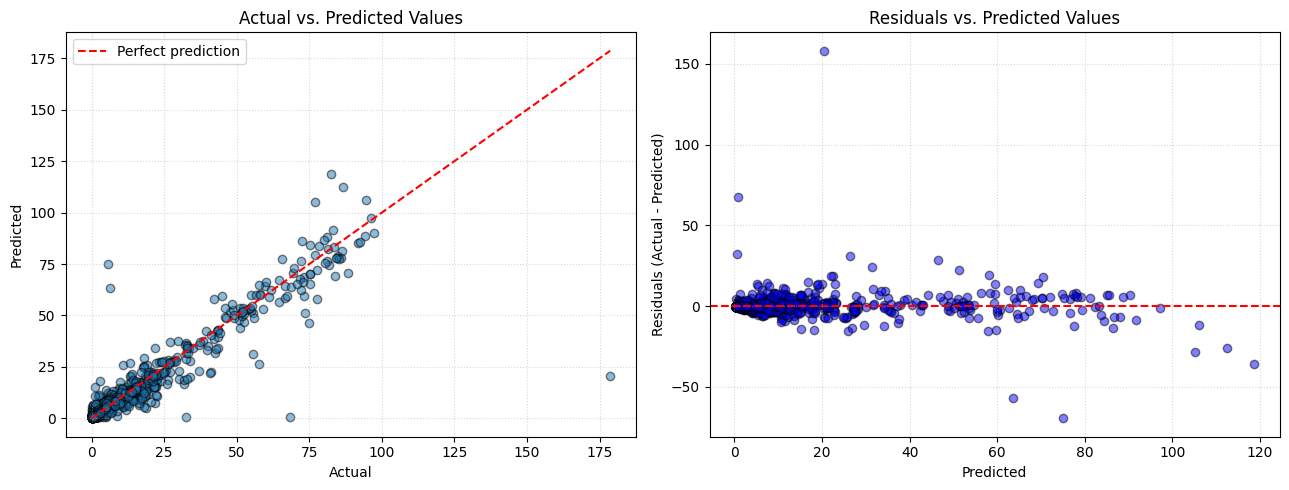

In [ ]:
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ----- Actual vs. predicted -----

axes[0].scatter(
    y_test,
    y_pred,
    alpha=0.5,
    edgecolors="black"
)

low = min(np.min(y_test), np.min(y_pred))
high = max(np.max(y_test), np.max(y_pred))

axes[0].plot(
    [low, high],
    [low, high],
    "r--",
    linewidth=1.5,
    label="Perfect prediction"
)

axes[0].set_title("Actual vs. Predicted Values")
axes[0].set_xlabel("Actual")
axes[0].set_ylabel("Predicted")
axes[0].legend()
axes[0].grid(True, linestyle=":", alpha=0.5)

# ----- Residual plot -----

axes[1].scatter(
    y_pred,
    residuals,
    color="blue",
    alpha=0.5,
    edgecolors="black"
)

axes[1].axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=1.5
)

axes[1].set_title("Residuals vs. Predicted Values")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Residuals (Actual - Predicted)")
axes[1].grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
train_sizes, train_scores, validation_scores = learning_curve(
    estimator=best_rf_model,
    X=X_train,
    y=y_train,

    # Use the same evaluation metric as the tuning process
    scoring="neg_root_mean_squared_error",

    cv=5,
    train_sizes=np.linspace(0.1, 1.0, 8),
    n_jobs=-1,
    shuffle=True,
    random_state=42
)

# Convert negative scores back to positive RMSE values
train_rmse_mean = -train_scores.mean(axis=1)
train_rmse_std = train_scores.std(axis=1)

validation_rmse_mean = -validation_scores.mean(axis=1)
validation_rmse_std = validation_scores.std(axis=1)

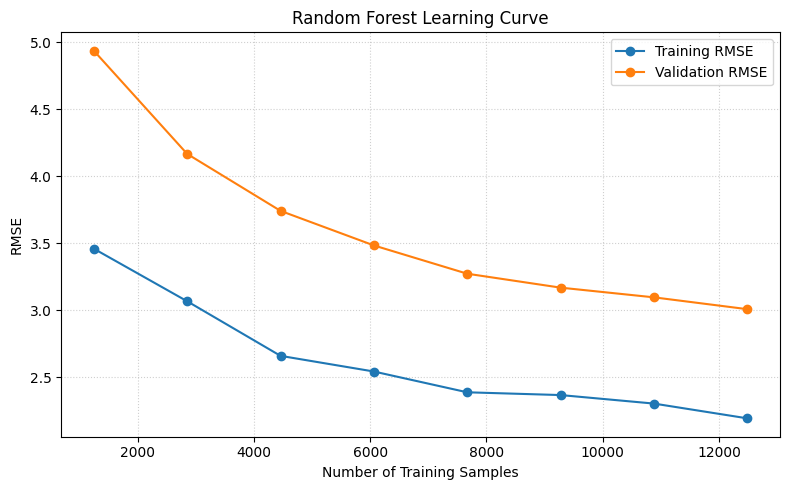

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    train_sizes,
    train_rmse_mean,
    marker="o",
    label="Training RMSE"
)

plt.plot(
    train_sizes,
    validation_rmse_mean,
    marker="o",
    label="Validation RMSE"
)

plt.title("Random Forest Learning Curve")
plt.xlabel("Number of Training Samples")
plt.ylabel("RMSE")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

### XGBoostRegressor

#### Import and split validation set

In [ ]:
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [ ]:
# split training set to train and validation
X_train_, X_val_, y_train_, y_val_ = train_test_split(X_train, y_train, test_size=0.2, random_state=25)

In [ ]:
preprocessor.fit(X_train_)
X_train_proc = preprocessor.transform(X_train_)
X_val_proc = preprocessor.transform(X_val_)

print("Training shape:", X_train_proc.shape)
print("Validation shape:", X_val_proc.shape)

Training shape: (12486, 99)
Validation shape: (3122, 99)


#### XGBoost 01

##### Train model

In [ ]:
xgb_model = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    early_stopping_rounds=30,
    random_state=25,
    n_jobs=-1,
    eval_metric='rmse'
)

xgb_model.fit(
    X_train_proc, y_train_,
    eval_set=[(X_train_proc, y_train_), (X_val_proc, y_val_)],
    verbose=False
)
print(f"Best iteration: {xgb_model.best_iteration}")
print(f"Best validation RMSE: {xgb_model.best_score:.3f}")

Best iteration: 652
Best validation RMSE: 3.412


##### Plot training curve

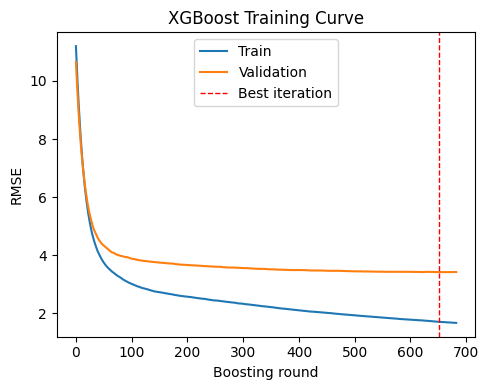

In [ ]:
## training curve
results = xgb_model.evals_result()
fix, ax = plt.subplots(figsize=(5,4))

ax.plot(results["validation_0"]["rmse"], label="Train")
ax.plot(results["validation_1"]["rmse"], label="Validation")
ax.axvline(xgb_model.best_iteration, color="r", linestyle="--", lw=1, label="Best iteration")

ax.set_xlabel("Boosting round")
ax.set_ylabel("RMSE")
ax.set_title("XGBoost Training Curve")
ax.legend()

plt.tight_layout()
plt.show()

##### Evaluate model on test set

In [ ]:
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ('regressor', xgb_model)
])

y_pred = xgb_pipeline.predict(X_test) # fit X_test to pipeline will automatically apply preprocessing data

r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

print(f"R2   = {r2:.3f}")
print(f"RMSE = {rmse:.3f}")
print(f"MAE  = {mae:.3f}")

R2   = 0.892
RMSE = 3.844
MAE  = 0.996


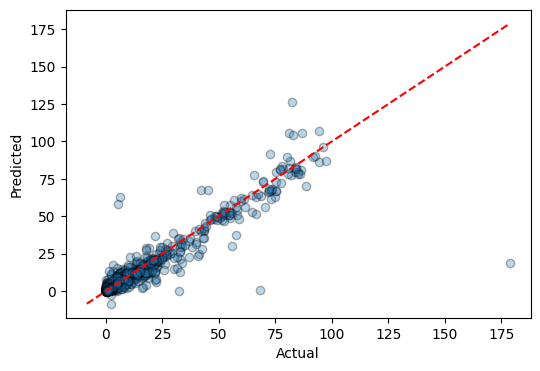

In [ ]:
## Actual vs predicted
plt.figure(figsize=(6, 4))

plt.scatter(x=y_test, y=y_pred, alpha=0.3, edgecolors='k')
lo = min(y_test.min(), y_pred.min())
hi = max(y_test.max(), y_pred.max())
plt.plot([lo, hi], [lo, hi], "r--", lw=1.5, label="Perfect prediction")

plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.show()

In [ ]:
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ----- Actual vs. predicted -----

axes[0].scatter(
    y_test,
    y_pred,
    alpha=0.5,
    edgecolors="black"
)

low = min(np.min(y_test), np.min(y_pred))
high = max(np.max(y_test), np.max(y_pred))

axes[0].plot(
    [low, high],
    [low, high],
    "r--",
    linewidth=1.5,
    label="Perfect prediction"
)

axes[0].set_title("Actual vs. Predicted Values")
axes[0].set_xlabel("Actual")
axes[0].set_ylabel("Predicted")
axes[0].legend()
axes[0].grid(True, linestyle=":", alpha=0.5)

# ----- Residual plot -----

axes[1].scatter(
    y_pred,
    residuals,
    color="blue",
    alpha=0.5,
    edgecolors="black"
)

axes[1].axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=1.5
)

axes[1].set_title("Residuals vs. Predicted Values")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Residuals (Actual - Predicted)")
axes[1].grid(True, linestyle=":", alpha=0.5)

plt.title('')
plt.tight_layout()
plt.show()

#### Hyperparams tuning

##### Training model

In [ ]:
# XGB pipeline
from sklearn.base import clone
xgb_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("regressor", XGBRegressor(
                    objective="reg:squarederror",
                    eval_metric='rmse',
                    tree_method='hist',
                    random_state=25,
                    n_jobs=1
                )
    )])

In [ ]:
# Hyperparams
xgb_params = {
    'regressor__n_estimators': [900, 1200, 1500],
    'regressor__learning_rate': [0.03, 0.05, 0.08],
    'regressor__max_depth': [3, 5],
    'regressor__subsample': [0.8],
}

In [ ]:
# KFold cross-validation
kfold = KFold(n_splits=5, shuffle=True, random_state=25)

In [ ]:
# Configure grid search
xgb_grid_search = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=xgb_params,
    scoring='neg_root_mean_squared_error',
    cv=kfold,
    n_jobs=-1,
    verbose=2,
    return_train_score=True
)

In [ ]:
# Hyperparams tuning
xgb_grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 18 candidates, totalling 90 fits


GridSearchCV(cv=KFold(n_splits=5, random_state=25, shuffle=True),
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('numeric',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['ph',
                                                                          'pesticide_rate',
                                                                          'avg_humidity_percent',
                                                                          'avg_temp_c',
                                                                          'n',
                                                                          'p',
                                                                          'fertilizer_rate',
                                                                          'total_rainfall_mm',
                                                                          'k']),...
                                                     missing=nan,
                                                     monotone_constraints=None,
                                                     multi_strategy=None,
                                                     n_estimators=None,
                                                     n_jobs=1,
                                                     num_parallel_tree=None, ...))]),
             n_jobs=-1,
             param_grid={'regressor__learning_rate': [0.03, 0.05, 0.08],
                         'regressor__max_depth': [3, 5],
                         'regressor__n_estimators': [900, 1200, 1500],
                         'regressor__subsample': [0.8]},
             return_train_score=True, scoring='neg_root_mean_squared_error',
             verbose=2)

In [ ]:
print("Best cross-validation RMSE: ", -xgb_grid_search.best_score_)
for p, v in xgb_grid_search.best_params_.items():
    print(f'{p}: {v}')

Best cross-validation RMSE:  3.0669235963337966
regressor__learning_rate: 0.03
regressor__max_depth: 5
regressor__n_estimators: 1500
regressor__subsample: 0.8


##### Compare tuning result

In [ ]:
tuning_results = pd.DataFrame(xgb_grid_search.cv_results_)

tuning_results['train_rmse'] = (-tuning_results['mean_train_score']) # Because of using negative rmse --> negative values
tuning_results['validation_rmse'] = (-tuning_results['mean_test_score'])

# large possitive value can indicate overfitting
tuning_results['overfitting_gap'] = (tuning_results['validation_rmse'] - tuning_results['train_rmse'])

comparison_columns = [
    "rank_test_score",
    "param_regressor__n_estimators",
    "param_regressor__learning_rate",
    "param_regressor__max_depth",
    "train_rmse",
    "validation_rmse",
    "overfitting_gap"
]

tuning_comparison = (
    tuning_results[comparison_columns]
    .sort_values(
        by="rank_test_score",               # Put the best model first
        ascending=True
    )
    .reset_index(
        drop=True                           # Reset row numbers
    )
)

display(tuning_comparison)

,rank_test_score,param_regressor__n_estimators,param_regressor__learning_rate,param_regressor__max_depth,train_rmse,validation_rmse,overfitting_gap
0,1,1500,0.03,5,0.977766,3.066924,2.089158
1,2,1200,0.03,5,1.137569,3.069946,1.932376
2,3,900,0.03,5,1.364579,3.073453,1.708874
3,4,900,0.08,5,0.689726,3.088102,2.398376
4,5,900,0.05,5,0.971539,3.100310,2.128771
5,6,1200,0.08,5,0.549793,3.101616,2.551823
6,7,1500,0.08,3,1.563142,3.104355,1.541213
7,8,1200,0.05,5,0.795848,3.106169,2.310321
8,9,1200,0.08,3,1.709341,3.107139,1.397798
9,10,1500,0.05,3,1.886536,3.108514,1.221978


##### Best estimator

In [ ]:
best_xgb = xgb_grid_search.best_estimator_

print("Best cross-validation RMSE:", -xgb_grid_search.best_score_)
print("\nBest parameters:")
for parameter, value in xgb_grid_search.best_params_.items():
    print(f"{parameter}: {value}")

Best cross-validation RMSE: 3.0669235963337966

Best parameters:
regressor__learning_rate: 0.03
regressor__max_depth: 5
regressor__n_estimators: 1500
regressor__subsample: 0.8


In [ ]:
# Evaluate best estimator
y_pred_ = best_xgb.predict(X_test) # no need to preprocess x test cuz model included preprocessor

mae = mean_absolute_error(y_test, y_pred_)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_))
r2 = r2_score(y_test, y_pred_)

print(f"Test MAE:  {mae:.3f}")
print(f"Test RMSE: {rmse:.3f}")
print(f"Test R²:   {r2:.3f}")

Test MAE:  0.889
Test RMSE: 3.825
Test R²:   0.893


In [ ]:
# Re-train model with best estimator
best_xgb_params = {
    param.replace('regressor__', ''): value
    for param, value in xgb_grid_search.best_params_.items()
}

xgb_model_ = XGBRegressor(
    **best_xgb_params,
    early_stopping_rounds=30,
    random_state=25,
    n_jobs=-1,
    eval_metric='rmse'
)

xgb_model_.fit(
    X_train_proc, y_train_,
    eval_set=[(X_train_proc, y_train_), (X_val_proc, y_val_)],
    verbose=False
)
print(f"Best iteration: {xgb_model_.best_iteration}")
print(f"Best validation RMSE: {xgb_model_.best_score:.3f}")

Best iteration: 871
Best validation RMSE: 3.383


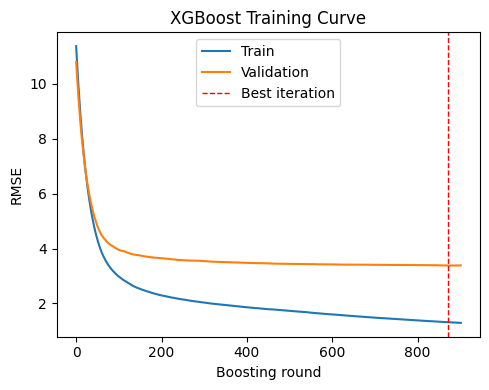

In [ ]:
## training curve
results = xgb_model_.evals_result()
fix, ax = plt.subplots(figsize=(5,4))

ax.plot(results["validation_0"]["rmse"], label="Train")
ax.plot(results["validation_1"]["rmse"], label="Validation")
ax.axvline(xgb_model_.best_iteration, color="r", linestyle="--", lw=1, label="Best iteration")

ax.set_xlabel("Boosting round")
ax.set_ylabel("RMSE")
ax.set_title("XGBoost Training Curve")
ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ('regressor', xgb_model_)
])

y_pred_1 = xgb_pipeline.predict(X_test) # fit X_test to pipeline will automatically apply preprocessing data

r2 = r2_score(y_test, y_pred_1)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_1))
mae = mean_absolute_error(y_test, y_pred_1)

print(f"R2   = {r2:.3f}")
print(f"RMSE = {rmse:.3f}")
print(f"MAE  = {mae:.3f}")

R2   = 0.890
RMSE = 3.874
MAE  = 0.945


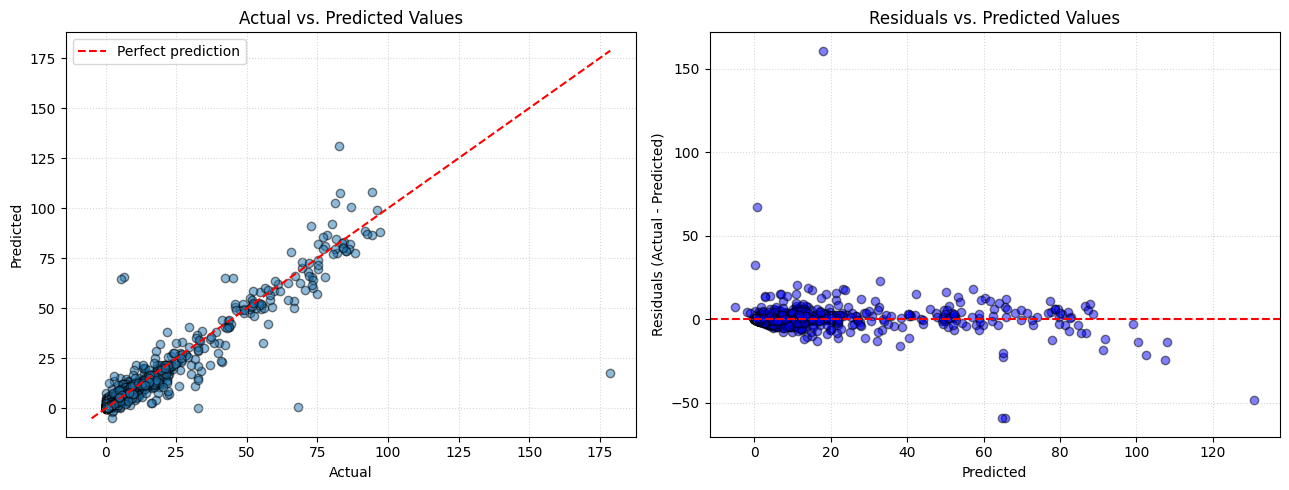

In [ ]:
residuals = y_test - y_pred_1

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes = axes.flatten()
# ----- Actual vs. predicted -----

axes[0].scatter(
    y_test,
    y_pred_1,
    alpha=0.5,
    edgecolors="black"
)

low = min(np.min(y_test), np.min(y_pred_1))
high = max(np.max(y_test), np.max(y_pred_1))

axes[0].plot(
    [low, high],
    [low, high],
    "r--",
    linewidth=1.5,
    label="Perfect prediction"
)

axes[0].set_title("Actual vs. Predicted Values")
axes[0].set_xlabel("Actual")
axes[0].set_ylabel("Predicted")
axes[0].legend()
axes[0].grid(True, linestyle=":", alpha=0.5)

# ----- Residual plot -----

axes[1].scatter(
    y_pred_1,
    residuals,
    color="blue",
    alpha=0.5,
    edgecolors="black"
)

axes[1].axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=1.5
)

axes[1].set_title("Residuals vs. Predicted Values")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Residuals (Actual - Predicted)")
axes[1].grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

##### Early stopping with Best XGBoost Parameters

In [ ]:
best_xgb_params = {
    param.replace('regressor__', ''): value
    for param, value in xgb_grid_search.best_params_.items()
}

# Early stopping will determine the best number of trees
# --> remove the value selected (n_estimators)
best_xgb_params.pop('n_estimators', None) # if key does not exist --> rm None

print("Best XGB params: ", best_xgb_params)

Best XGB params:  {'learning_rate': 0.03, 'max_depth': 5, 'subsample': 0.8}


In [ ]:
# preprocess X_train_
early_stop_preprocessor = clone(preprocessor)

early_stop_preprocessor.fit(X_train_)
X_train_proc = early_stop_preprocessor.transform(X_train_)

X_val_proc = early_stop_preprocessor.transform(X_val_)

In [ ]:
# Training model with early stop
es_xgb = XGBRegressor(
    **best_xgb_params,
    early_stopping_rounds=50,

    objective="reg:squarederror",
    eval_metric='rmse',
    tree_method='hist',
    random_state=25,
    n_jobs=-1
)


In [ ]:
es_xgb.fit(
    X_train_proc, y_train_,
    eval_set=[
        (X_train_proc, y_train_),
        (X_val_proc, y_val_)
    ],
    verbose=False
    )

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=50,
             enable_categorical=True, eval_metric='rmse', feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.03, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=-1, num_parallel_tree=None, ...)

In [ ]:
best_n_estimators = es_xgb.best_iteration + 1 # because of zero-based indexing

print("Best iteration:", es_xgb.best_iteration)
print("Selected number of trees:", best_n_estimators)
print("Best validation RMSE:", es_xgb.best_score)

Best iteration: 99
Selected number of trees: 100
Best validation RMSE: 3.963466044394929


##### Early-stopping training curves

In [ ]:
evaluation_results = es_xgb.evals_result()
training_rmse = evaluation_results['validation_0']['rmse']
val_rmse = evaluation_results['validation_1']['rmse']
print(evaluation_results.keys())


dict_keys(['validation_0', 'validation_1'])


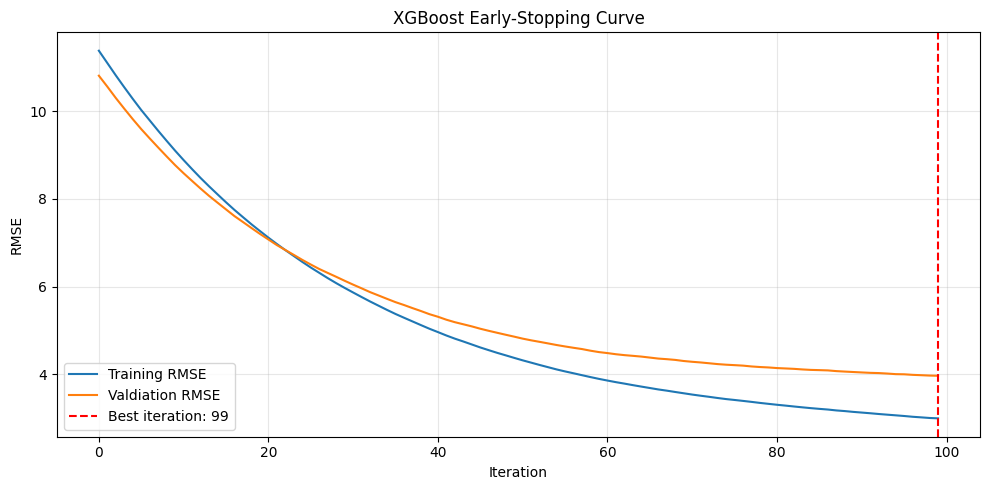

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(
    training_rmse,
    label='Training RMSE'
)

plt.plot(
    val_rmse,
    label='Valdiation RMSE'
)

plt.axvline(
    x=es_xgb.best_iteration,
    color="red",
    linestyle="--",
    label=f"Best iteration: {es_xgb.best_iteration}"
)

plt.xlabel("Iteration")
plt.ylabel("RMSE")
plt.title("XGBoost Early-Stopping Curve")
plt.legend()
plt.grid(
    alpha=0.3                                 # Display a light grid
)
plt.tight_layout()
plt.show()

##### Final model

In [ ]:
# preprocess X_train_
final_preprocessor = clone(preprocessor)

final_preprocessor.fit(X_train)
X_train_final_proc = final_preprocessor.transform(X_train)

X_test_proc = final_preprocessor.transform(X_test)

In [ ]:
final_xgb_model = XGBRegressor(
    **best_xgb_params,
    n_estimators=best_n_estimators,
    objective="reg:squarederror",
    eval_metric="rmse",
    tree_method="hist",
    random_state=25,
    n_jobs=-1
)

In [ ]:
final_xgb_model.fit(
    X_train_final_proc,
    y_train
)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric='rmse', feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.03, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=-1, num_parallel_tree=None, ...)

In [ ]:
y_pred = final_xgb_model.predict(X_test_proc)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Test MAE:  {mae:.3f}")
print(f"Test RMSE: {rmse:.3f}")
print(f"Test R²:   {r2:.3f}")

Test MAE:  1.678
Test RMSE: 4.309
Test R²:   0.864


##### Plots

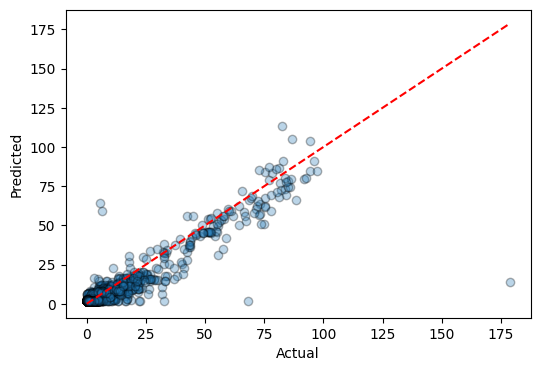

In [ ]:
## Actual vs predicted
plt.figure(figsize=(6, 4))

plt.scatter(x=y_test, y=y_pred, alpha=0.3, edgecolors='k')
lo = min(y_test.min(), y_pred.min())
hi = max(y_test.max(), y_pred.max())
plt.plot([lo, hi], [lo, hi], "r--", lw=1.5, label="Perfect prediction")

plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.show()

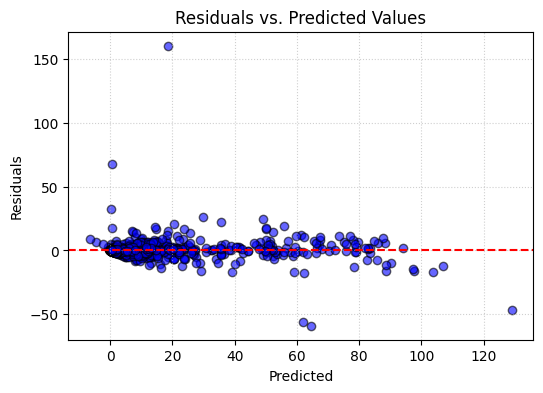

In [ ]:
# Residual plot
residuals = y_test - y_pred

plt.figure(figsize=(6, 4))
plt.scatter(y_pred, residuals, color='blue', alpha=0.6, edgecolors='k')

# Add a horizontal reference line at y = 0
plt.axhline(y=0, color='red', linestyle='--', linewidth=1.5)

# Axis labels and styling
plt.title('Residuals vs. Predicted Values')
plt.xlabel('Predicted')
plt.ylabel('Residuals')
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()

### LSTM

##### Import and initialize

In [ ]:
import random
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.layers import Dense, Dropout, GRU, Input, LSTM

In [ ]:
SEED = 25
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

LOOKBACK = 3
TRAIN_END_YEAR = 2016
VAL_END_YEAR = 2018
BATCH_SIZE = 64
EPOCHS = 100

##### Prepare data

In [ ]:
df = merged_df.copy()

In [ ]:
df['year'].unique()

array(['1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
       '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012',
       '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020'],
      dtype=object)

In [ ]:
df['year'] = df['year'].astype(int)
df['year'].dtype

dtype('int64')

In [ ]:
series_cols = ["crop", "state", "season"]  # Identify each time series

numeric_features = [
    "p",
    "k",
    "fertilizer_rate",
    "pesticide_rate",
    "ph",
    "avg_temp_c",
    "n",
    "avg_humidity_percent",
    "total_rainfall_mm",
]

In [ ]:
# Sort each crop-state-season series chronologically
df = df.sort_values(series_cols + ["year"]).reset_index(drop=True)
df.duplicated().any()

np.False_

In [ ]:
encoded = pd.get_dummies(
    df,
    columns=series_cols,
    prefix=series_cols,
    dtype=float,
)

categorical_features = [
    c for c in encoded.columns
    if c.startswith(("crop_", "state_", "season_"))
]

feature_cols = numeric_features + categorical_features

feature_cols

['p',
 'k',
 'fertilizer_rate',
 'pesticide_rate',
 'ph',
 'avg_temp_c',
 'n',
 'avg_humidity_percent',
 'total_rainfall_mm',
 'crop_arecanut',
 'crop_arhar/tur',
 'crop_bajra',
 'crop_banana',
 'crop_barley',
 'crop_black_pepper',
 'crop_cardamom',
 'crop_cashewnut',
 'crop_castor_seed',
 'crop_coriander',
 'crop_cotton(lint)',
 'crop_cowpea(lobia)',
 'crop_dry_chillies',
 'crop_garlic',
 'crop_ginger',
 'crop_gram',
 'crop_groundnut',
 'crop_guar_seed',
 'crop_horse_gram',
 'crop_jowar',
 'crop_jute',
 'crop_khesari',
 'crop_linseed',
 'crop_maize',
 'crop_masoor',
 'crop_mesta',
 'crop_moong(green_gram)',
 'crop_moth',
 'crop_niger_seed',
 'crop_oilseeds_total',
 'crop_onion',
 'crop_other__rabi_pulses',
 'crop_other_cereals',
 'crop_other_kharif_pulses',
 'crop_other_oilseeds',
 'crop_other_summer_pulses',
 'crop_peas_&_beans_(pulses)',
 'crop_potato',
 'crop_ragi',
 'crop_rapeseed_&mustard',
 'crop_rice',
 'crop_safflower',
 'crop_sannhamp',
 'crop_sesamum',
 'crop_small_millets',

In [ ]:
# Reattach compact series keys for reliable grouping after one-hot encoding.
encoded["_series_key"] = list(zip(df["crop"], df["state"], df["season"]))
print("Number of time series:", encoded["_series_key"].nunique())

Number of time series: 1671


In [ ]:
encoded['_series_key']

,_series_key
0,"(arecanut, andhra_pradesh, kharif)"
1,"(arecanut, andhra_pradesh, kharif)"
2,"(arecanut, andhra_pradesh, kharif)"
3,"(arecanut, andhra_pradesh, kharif)"
4,"(arecanut, andhra_pradesh, kharif)"
...,...
19505,"(wheat, west_bengal, rabi)"
19506,"(wheat, west_bengal, rabi)"
19507,"(wheat, west_bengal, rabi)"
19508,"(wheat, west_bengal, rabi)"


In [ ]:
encoded.columns

Index(['year', 'yield', 'avg_temp_c', 'total_rainfall_mm',
       'avg_humidity_percent', 'n', 'p', 'k', 'ph', 'fertilizer_rate',
       ...
       'state_uttar_pradesh', 'state_uttarakhand', 'state_west_bengal',
       'season_autumn', 'season_kharif', 'season_rabi', 'season_summer',
       'season_whole_year', 'season_winter', '_series_key'],
      dtype='object', length=102)

In [ ]:
df.head(10)

,crop,year,season,state,yield,avg_temp_c,total_rainfall_mm,avg_humidity_percent,n,p,k,ph,fertilizer_rate,pesticide_rate
0,arecanut,2012,kharif,andhra_pradesh,1.453333,27.87,1192.65,70.20,78,45,22,6.8,150.80,0.31
1,arecanut,2013,kharif,andhra_pradesh,1.705000,27.45,1279.53,72.34,78,45,22,6.8,144.49,0.27
2,arecanut,2014,kharif,andhra_pradesh,1.775000,28.18,749.08,66.95,78,45,22,6.8,150.96,0.33
3,arecanut,2015,kharif,andhra_pradesh,3.320000,28.21,824.00,67.96,78,45,22,6.8,157.91,0.33
4,arecanut,2016,kharif,andhra_pradesh,3.912500,28.04,935.87,68.69,78,45,22,6.8,153.25,0.35
5,arecanut,2017,kharif,andhra_pradesh,5.582500,28.14,991.20,69.86,78,45,22,6.8,157.44,0.38
6,arecanut,2018,kharif,andhra_pradesh,4.153333,28.18,927.05,67.40,78,45,22,6.8,162.20,0.35
7,arecanut,2019,kharif,andhra_pradesh,7.253333,28.20,1027.80,71.25,78,45,22,6.8,171.76,0.37
8,arecanut,2000,whole_year,andhra_pradesh,2.780000,27.74,1070.25,70.73,78,45,22,6.8,98.17,0.26
9,arecanut,2001,whole_year,andhra_pradesh,1.710000,28.08,910.13,68.69,78,45,22,6.8,102.13,0.26


In [ ]:
df.shape

(19510, 14)

##### Create consecutive-year sequences

In [ ]:
def create_sequences(data, feature_columns, lookback=3):
    X_sequences = []
    y_targets = []
    target_years = []

    # Process every crop-state-season serires separately
    for _, group in data.groupby('_series_key', sort=False):
        group = group.sort_values('year').reset_index(drop=True)

        # Move window through the series
        for end_idx in range(lookback - 1, len(group)):
            start_idx = end_idx - lookback + 1  # window's first row

            window =  group.iloc[start_idx : end_idx+1]

            years = window['year'].to_numpy()

            # if not np.all(np.diff(years) == 1): # detect missing years
            #     continue                        # skip non-consecutive sequence

            X_sequences.append(window[feature_columns].to_numpy(dtype=np.float32)) # convert to np array

            y_targets.append(np.float32(window.iloc[-1]['yield']))   # yield in final year of the window

            target_years.append(window.iloc[-1]['year'])  # target year

    return (
        np.asarray(X_sequences, dtype=np.float32),
        np.asarray(y_targets, dtype=np.float32),
        np.asarray(target_years, dtype=np.int32),
    )


In [ ]:
X_seq, y_seq, sequence_years = create_sequences(
    encoded,
    feature_columns=feature_cols,
    lookback=LOOKBACK
)

print("X shape:", X_seq.shape)
print("y shape:", y_seq.shape)
print("First target year:", sequence_years.min())
print("Last target year:", sequence_years.max())
sequence_years

X shape: (16385, 3, 99)
y shape: (16385,)
First target year: 1999
Last target year: 2020


array([2014, 2015, 2016, ..., 2017, 2018, 2019], dtype=int32)

In [ ]:
y_seq

array([1.775], dtype=float32)

##### Data split

In [ ]:
train_mask = sequence_years <= TRAIN_END_YEAR  # Select targets up to 2016

val_mask = (
    (sequence_years > TRAIN_END_YEAR)  # Exclude training years
    & (sequence_years <= VAL_END_YEAR)  # Include 2017 and 2018
)

test_mask = sequence_years > VAL_END_YEAR  # Select 2019 and 2020 targets

X_train_lstm = X_seq[train_mask]
y_train_lstm = y_seq[train_mask]

X_val_lstm = X_seq[val_mask]
y_val_lstm = y_seq[val_mask]

X_test_lstm = X_seq[test_mask]
y_test_lstm = y_seq[test_mask]

print("Training:", X_train_lstm.shape, y_train_lstm.shape)
print("Validation:", X_val_lstm.shape, y_val_lstm.shape)
print("Testing:", X_test_lstm.shape, y_test_lstm.shape)

print("Validation years:", np.unique(sequence_years[val_mask]))  # Find unique validation years
print("Test years:", np.unique(sequence_years[test_mask]))

Training: (13330, 3, 99) (13330,)
Validation: (1991, 3, 99) (1991,)
Testing: (1064, 3, 99) (1064,)
Validation years: [2017 2018]
Test years: [2019 2020]


##### Scale input features and target

In [ ]:
x_scaler = StandardScaler()
y_scaler = StandardScaler()

n_numeric = len(numeric_features)  # Count numerical features

numeric_indices = list(range(n_numeric))  # Numerical features appear before one-hot features

# Scale 3D LSTM inputs
def scale_sequence_features(X, scaler, fit=False):
    """Scale numeric features without changing one-hot features."""

    X_scaled = X.copy()

    # Select only numerical values
    numeric_values = X_scaled[:, :, numeric_indices].reshape(-1, n_numeric)

    # Check whether this is training data
    if fit:
        numeric_values = scaler.fit_transform(numeric_values)
    else:  # Handle validation or testing data
        numeric_values = scaler.transform(numeric_values)
    # Replace original numerical values
    X_scaled[:, :, numeric_indices] = numeric_values.reshape(X_scaled.shape[0], X_scaled.shape[1], n_numeric)

    return X_scaled

# Scale training inputs
X_train_scaled = scale_sequence_features(X_train_lstm, x_scaler, fit=True)
# Scale validation inputs
X_val_scaled = scale_sequence_features(X_val_lstm, x_scaler, fit=False)
# Scale testing inputs
X_test_scaled = scale_sequence_features(X_test_lstm, x_scaler, fit=False)

In [ ]:
# Target
# Learn and apply target scaling
y_train_scaled = y_scaler.fit_transform(y_train_lstm.reshape(-1, 1)).ravel()  # Convert the result back to 1D

y_val_scaled = y_scaler.transform(y_val_lstm.reshape(-1, 1)).ravel()

##### Build LSTM model

In [ ]:
lstm_model = Sequential([  # Create a layer-by-layer model
    Input(shape=(LOOKBACK, len(feature_cols))),  # Use timesteps × features

    LSTM(
        units=64,
        return_sequences=True,  # Pass every timestep to the next LSTM
    ),

    Dropout(rate=0.2),  # Drop 20% to reduce overfitting

    LSTM(
        units=32,
        return_sequences=False,  # Return only the final LSTM output
    ),

    Dropout(rate=0.20),  # Drop 20%

    Dense(
        units=16,  # Use 16 hidden neurons
        activation="relu",  # Learn non-linear relationships
    ),

    Dense(units=1),  # Predict one yield value
])



In [ ]:
# Configure the training process
lstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse",
    metrics=[
        tf.keras.metrics.RootMeanSquaredError(
            name="rmse"
        ),
        tf.keras.metrics.MeanAbsoluteError(
            name="mae"
        )
    ]
)

lstm_model.summary()  # Display the model architecture

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 3, 64)          │        41,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 3, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 54,945 (214.63 KB)

 Trainable params: 54,945 (214.63 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
## Configure training callbacks

early_stopping = EarlyStopping(     # Stop before the model overfits
    monitor="val_loss",             # Monitor validation MSE
    patience=15,                    # Wait 15 epochs for improvement
    restore_best_weights=True,      # Return to the best model weights
    verbose=1,                      # Display when training stops
)

reduce_lr = ReduceLROnPlateau(      # Lower LR when improvement becomes slow
    monitor="val_loss",             # Monitor validation MSE
    factor=0.5,                     # Divide the learning rate by two
    patience=5,                     # Wait five epochs before reducing LR
    min_lr=1e-6,                    # Prevent the learning rate becoming too small
    verbose=1,                      # Display each learning-rate reduction
)

##### Training LSTM model

In [ ]:
history = lstm_model.fit(
    X_train_scaled,
    y_train_scaled,
    validation_data=(
        X_val_scaled,
        y_val_scaled,
    ),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[  #
        early_stopping,
        reduce_lr,
    ],
    shuffle=True,
    verbose=1,
)

Epoch 1/100
209/209 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - loss: 0.4495 - mae: 0.2700 - rmse: 0.6704 - val_loss: 0.2474 - val_mae: 0.1872 - val_rmse: 0.4974 - learning_rate: 0.0010
Epoch 2/100
209/209 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.1518 - mae: 0.1582 - rmse: 0.3896 - val_loss: 0.2399 - val_mae: 0.1698 - val_rmse: 0.4898 - learning_rate: 0.0010
Epoch 3/100
209/209 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 0.1259 - mae: 0.1433 - rmse: 0.3548 - val_loss: 0.2197 - val_mae: 0.1645 - val_rmse: 0.4688 - learning_rate: 0.0010
Epoch 4/100
209/209 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.1172 - mae: 0.1346 - rmse: 0.3423 - val_loss: 0.1631 - val_mae: 0.1400 - val_rmse: 0.4038 - learning_rate: 0.0010
Epoch 5/100
209/209 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.1071 - mae: 0.1259 - rmse: 0.3273 - val_loss: 0.1415 - val_mae: 0.1272 - val_rmse: 0.3762 - learning_rate: 0.0010
Epoch 6/100
209/209 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0955 - mae: 0.1200 - rmse: 0.3090 - val_loss: 0.16

##### Evaluate model

In [ ]:
y_pred_scaled = lstm_model.predict(  #
    X_test_scaled,
    verbose=0,
)

y_pred_lstm = y_scaler.inverse_transform(
    y_pred_scaled
).ravel()  # Convert predictions into a 1D array

mae = mean_absolute_error(
    y_test_lstm,
    y_pred_lstm,
)

rmse = np.sqrt(
    mean_squared_error(
        y_test_lstm,
        y_pred_lstm,
    )
)

r2 = r2_score(
    y_test_lstm,
    y_pred_lstm,
)

print(f"Test MAE:  {mae:.3f}")  # Display MAE
print(f"Test RMSE: {rmse:.3f}")  # Display RMSE
print(f"Test R²:   {r2:.3f}")  # Display R-squared

Test MAE:  1.261
Test RMSE: 3.034
Test R²:   0.937


##### Plots training curve

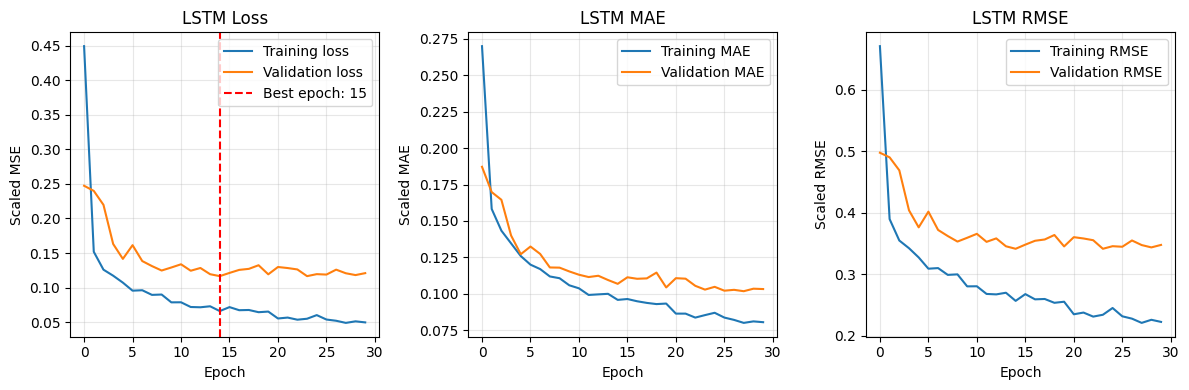

In [ ]:
best_epoch = np.argmin(history.history["val_loss"]) + 1

fig, axes = plt.subplots(nrows=1,ncols=3,  figsize=(12, 4))

axes[0].plot(history.history["loss"], label="Training loss")

axes[0].plot(history.history["val_loss"], label="Validation loss")

# Mark the best epoch
axes[0].axvline(
    x=best_epoch - 1,
    color="red",
    linestyle="--",
    label=f"Best epoch: {best_epoch}",
)

axes[0].set_title("LSTM Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Scaled MSE")
axes[0].legend()
axes[0].grid(alpha=0.3)

 # Plot training MAE
axes[1].plot(
    history.history["mae"],
    label="Training MAE",
)

axes[1].plot(
    history.history["val_mae"],
    label="Validation MAE"
)

axes[1].set_title("LSTM MAE")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Scaled MAE")
axes[1].legend()
axes[1].grid(alpha=0.3)

# Plot training RMSE
axes[2].plot(
    history.history["rmse"],
    label="Training RMSE",
)

axes[2].plot(
    history.history["val_rmse"],
    label="Validation RMSE"
)

axes[2].set_title("LSTM RMSE")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Scaled RMSE")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

##### Evaluation plots

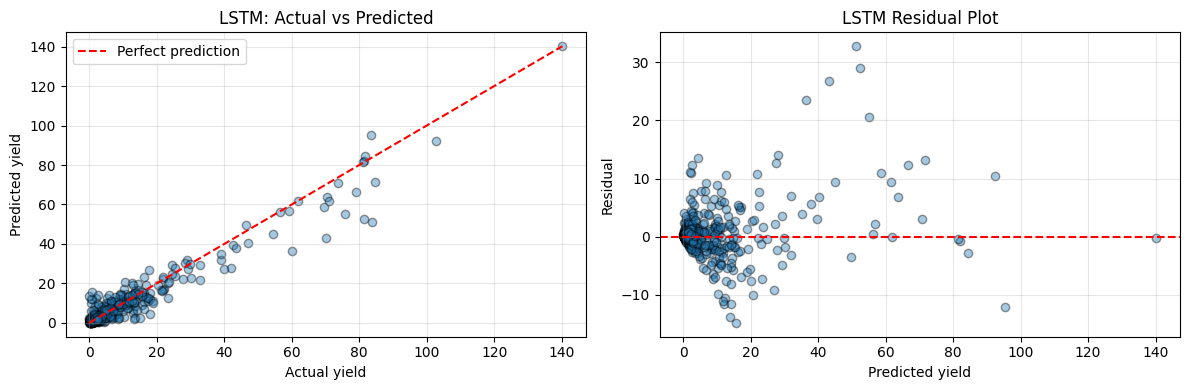

In [ ]:
residuals = y_test_lstm - y_pred_lstm

fig, axes = plt.subplots( nrows=1, ncols=2, figsize=(12, 4))

# ------------ Actual vs Predicted -----------------
axes[0].scatter(
    y_test_lstm,
    y_pred_lstm,
    alpha=0.4,
    edgecolors="k",  # Add black point borders
)

lower = min(y_test_lstm.min(), y_pred_lstm.min())

upper = max(y_test_lstm.max(),y_pred_lstm.max(), )
 # Draw the perfect-prediction reference line
axes[0].plot( [lower, upper],  [lower, upper],"r--", label="Perfect prediction")

axes[0].set_title("LSTM: Actual vs Predicted")
axes[0].set_xlabel("Actual yield")
axes[0].set_ylabel("Predicted yield")
axes[0].legend()
axes[0].grid(alpha=0.3)

# ------------ Residuals plot -----------------
axes[1].scatter(y_pred_lstm, residuals,  alpha=0.4,   edgecolors="k")

axes[1].axhline(y=0,color="red",  linestyle="--")

axes[1].set_title("LSTM Residual Plot")
axes[1].set_xlabel("Predicted yield")
axes[1].set_ylabel("Residual")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()